# Bước 5: Evaluator 1:N và baseline B0 trên validation
**Đồ án CV nâng cao · Nhóm A/B/C · 28/10/2026**

Notebook này dựng bộ đánh giá nhận diện **1:N có người lạ (open-set)** và chạy **B0** (InceptionResnetV1 pretrained VGGFace2, không fine-tune) trên **DigiFace validation**. Đây là mốc để so với B1/B2 ở bước 6.

Câu hỏi:
1. Ở mức nhận nhầm người lạ **FPIR ≤ 5%**, B0 nhận đúng bao nhiêu query của người đã đăng ký (**DIR**)?
2. Hai cách chuẩn bị ảnh ở bước 4 (A: resize thẳng, B: chạy lại MTCNN rồi crop) cho kết quả khác nhau thế nào khi tính cả ảnh lỗi trong mẫu số?
3. B0 sai ở đâu: nhận nhầm người lạ, nhầm sang người khác, hay từ chối người quen?

**Phạm vi:** chỉ ảnh validation. Không đọc ảnh train/test, không dùng ROF/MFR2 (theo quyết định P3), không fine-tune. Ngưỡng chọn ở đây là ngưỡng validation của B0, dùng làm mốc so sánh; ngưỡng cuối của từng model sẽ chọn lại theo cùng quy tắc.

Bản tiếp nối Codex 05/11: hash toàn bộ bytes validation trước dùng cache; export score đủ 17 chữ số và kiểm round-trip tại threshold.

## 1. Môi trường, cấu hình và hợp đồng đánh giá

Notebook đọc `protocol/notebook_outputs/protocol_draft.json` và kiểm từng điều khoản của `evaluation_contract` trước khi tính, để code không lệch khỏi protocol đã chốt. Cũng kiểm 5 quyết định P1–P5 đã được xác nhận trong `quyet_dinh_nhom/input/project_decisions.csv`.

In [1]:
from __future__ import annotations
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, os, time, platform, importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch
import torch.nn.functional as F
from facenet_pytorch import MTCNN, InceptionResnetV1
from facenet_pytorch.models.mtcnn import fixed_image_standardization

def find_root():
    candidates = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    candidates += [Path.cwd(), *Path.cwd().parents]
    for p in candidates:
        if (p/'ban_giao_nhom/danh_gia_b0/B0_evaluator_validation.ipynb').is_file(): return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt biến môi trường CV_PROJECT_ROOT.')

ROOT = find_root(); HERE = ROOT/'ban_giao_nhom/danh_gia_b0'; OUT = HERE/'notebook_outputs'
TAB, FIG, CACHE = OUT/'tables', OUT/'figures', OUT/'cache'
for p in [OUT, TAB, FIG, CACHE]: p.mkdir(parents=True, exist_ok=True)
PROTOCOL_DIR = ROOT/'ban_giao_nhom/protocol/notebook_outputs'
ROLE_PATH = PROTOCOL_DIR/'tables/05_image_roles_draft.csv'
DECISIONS_PATH = ROOT/'ban_giao_nhom/quyet_dinh_nhom/input/project_decisions.csv'
PILOT_DIR = ROOT/'ban_giao_nhom/preprocessing/notebook_outputs'
SEED = 20261028
CONFIG = {
    'version': 'b0_val_eval_v2_roundtrip', 'seed': SEED, 'partition': 'val', 'source': 'DigiFace',
    'encoder': 'InceptionResnetV1(pretrained=vggface2, classify=False).eval()',
    'pipelines': {'A': 'direct_resize_160_PIL_BILINEAR', 'B': 'MTCNN_redetect_exactly_one_face_then_extract_160'},
    'mtcnn': {'image_size': 160, 'margin': 0, 'min_face_size': 20, 'thresholds': [0.6, 0.7, 0.7], 'factor': 0.709},
    'standardization': '(pixel_0_255 - 127.5) / 128 applied once',
    'embedding': 'L2-normalized 512-d', 'batch_size': 256,
    'bootstrap_repetitions': 2000, 'primary_pipeline': 'A',
}
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 160)
STARTED = time.perf_counter()

def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''): h.update(b)
    return h.hexdigest()
def digest(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()
def save(frame, name):
    frame.to_csv(TAB/(name+'.csv'), index=False, encoding='utf-8-sig', float_format='%.17g'); return frame
def json_out(obj, name): (OUT/name).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
def finish(fig, name):
    for ext in ['png', 'svg']: fig.savefig(FIG/(name+'.'+ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)
def vn(x, digits=0): return f'{x:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')
def pct(x, digits=2): return vn(100*x, digits) + '%'

protocol = json.loads((PROTOCOL_DIR/'protocol_draft.json').read_text(encoding='utf-8'))
contract = protocol['evaluation_contract']
expected_contract = {
    'problem': 'open_set_identification_rank1',
    'primary_metric': 'DIR_at_empirical_validation_FPIR_target',
    'target_validation_fpir': 0.05,
    'threshold_selection': 'max_DIR_subject_to_empirical_FPIR_le_target; ties:higher_threshold',
    'score_accept_rule': 'top_cosine >= threshold',
    'gallery_template': 'mean_of_L2_embeddings_then_L2_normalize',
    'known_failure_denominator': 'all_input_known_queries',
    'unknown_failure_denominator': 'all_input_unknown_queries',
    'external_tuning_allowed': False,
}
for k, v in expected_contract.items():
    assert contract[k] == v, f'Hợp đồng đánh giá khác protocol: {k}={contract[k]!r}'
FPIR_TARGET = contract['target_validation_fpir']

decisions = pd.read_csv(DECISIONS_PATH, dtype=str, encoding='utf-8-sig')
expected_choice = {'P1': 'conservative_withhold', 'P2': 'base_gallery_3', 'P3': 'external_test_only',
                   'P4': 'fpir_05_empirical', 'P5': 'direct_resize_digiface'}
assert dict(zip(decisions.decision_id, decisions.chosen_option)) == expected_choice, 'P1–P5 khác lựa chọn notebook này giả định'
assert decisions.reviewer.str.len().gt(0).all()

ENV = {'python': platform.python_version(), 'torch': torch.__version__,
       'facenet_pytorch': importlib.metadata.version('facenet-pytorch'), 'numpy': np.__version__,
       'pandas': pd.__version__, 'device': DEVICE,
       'gpu': torch.cuda.get_device_name(0) if DEVICE.startswith('cuda') else None}
display(pd.DataFrame([ENV]).T.rename(columns={0: 'Giá trị'}))
display(decisions[['decision_id', 'chosen_option', 'reviewer', 'reviewed_at']])

H:\Nam tu\Hoc Ki 1\CV nang cao\Đồ Án\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Giá trị
python,3.11.9
torch,2.2.2+cu121
facenet_pytorch,2.6.0
numpy,1.26.4
pandas,2.2.3
device,cuda:0
gpu,NVIDIA GeForce RTX 4060 Laptop GPU


,decision_id,chosen_option,reviewer,reviewed_at
0,P1,conservative_withhold,Nguyen Tran Gia Bao,2026-10-28
1,P2,base_gallery_3,Nguyen Tran Gia Bao,2026-10-28
2,P3,external_test_only,Nguyen Tran Gia Bao,2026-10-28
3,P4,fpir_05_empirical,Nguyen Tran Gia Bao,2026-10-28
4,P5,direct_resize_digiface,Nguyen Tran Gia Bao,2026-10-28


## 2. Cohort validation

Lấy đúng các ảnh `partition=val` của DigiFace trong bảng vai trò của protocol: 100 người quen (mỗi người 3 ảnh gallery + 37 query) và 100 người lạ (mỗi người 40 query). Không đọc ảnh nào ngoài danh sách này. Theo P1, các ảnh bị tạm giữ đã nằm ngoài cohort; với DigiFace validation không có ảnh nào bị tạm giữ. Các ảnh có cờ QA (đuôi chất lượng, detector từng thất bại) **vẫn giữ** trong mẫu số.

In [2]:
roles = pd.read_csv(ROLE_PATH, dtype=str, keep_default_na=False)
V = roles[roles.partition.eq('val') & roles.source.eq('DigiFace')].copy()
V = V.sort_values('image_id').reset_index(drop=True)
assert V.image_id.is_unique and V.path.is_unique
counts = V.groupby(['identity_role', 'role']).agg(images=('image_id', 'size'), identities=('canonical_identity', 'nunique'))
assert counts.loc[('known', 'gallery'), 'images'] == 300 and counts.loc[('known', 'known_query'), 'images'] == 3700
assert counts.loc[('unknown', 'unknown_query'), 'images'] == 4000
assert counts.identities.eq(100).all()
known_ids = sorted(V[V.identity_role.eq('known')].canonical_identity.unique())
unknown_ids = sorted(V[V.identity_role.eq('unknown')].canonical_identity.unique())
assert not set(known_ids) & set(unknown_ids)
assert V.groupby('canonical_identity').partition.nunique().eq(1).all()
train_test_ids = set(roles[roles.partition.isin(['train', 'test'])].canonical_identity)
assert not train_test_ids & set(V.canonical_identity), 'Rò rỉ danh tính giữa val và train/test'
V['qa_flagged'] = V.qa_reasons.ne('')
VAL_SHA = hashlib.sha256(V.to_csv(index=False, lineterminator='\n').encode()).hexdigest()
display(counts.reset_index())
display(Markdown(f'Cohort: **{vn(len(V))} ảnh / {len(known_ids) + len(unknown_ids)} người**; '
                 f'{vn(V.qa_flagged.sum())} ảnh có cờ QA vẫn được giữ trong mẫu số.'))

# Cache chỉ hợp lệ khi bytes của TẤT CẢ ảnh validation vẫn khớp, không chỉ mẫu 40 ảnh.
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(max_workers=6) as pool:
    verified_raw=list(pool.map(lambda r: sha(ROOT/r.path)==r.sha256, V.itertuples()))
assert all(verified_raw), 'Raw validation đổi bytes; dừng trước inference/cache'


,identity_role,role,images,identities
0,known,gallery,300,100
1,known,known_query,3700,100
2,unknown,unknown_query,4000,100


Cohort: **8.000 ảnh / 200 người**; 231 ảnh có cờ QA vẫn được giữ trong mẫu số.

## 3. Chuẩn bị ảnh (A, B) và encoder

Dùng lại đúng quy ước đã kiểm ở bước 4:

- Mở ảnh sau khi SHA-256 khớp manifest; `exif_transpose`; ảnh có pixel trong suốt được ghép lên nền trắng; chuyển RGB.
- **A:** resize 160 × 160 (PIL BILINEAR).
- **B:** MTCNN tìm mọi bbox; chỉ khi có **đúng một** mặt mới crop bằng `MTCNN.extract`; không có mặt / nhiều mặt là thất bại có ghi lý do. Bbox được ép về `float` vì facenet-pytorch 2.6 trả mảng `dtype=object`.
- Pixel RGB uint8 → tensor float32 → chuẩn hóa `(x − 127,5)/128` đúng một lần → encoder → embedding 512 chiều chuẩn hóa L2.

Trọng số encoder được hash để gắn vào dấu vân tay cache.

In [3]:
def open_rgb(path, expected_sha):
    if sha(path) != expected_sha: raise ValueError('RAW_SHA_MISMATCH: ' + str(path))
    with Image.open(path) as source:
        source.load()
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba = im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A')) < 255).any():
                im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return im.convert('RGB').copy()

def face_status(boxes):
    if boxes is None: return 'no_face'
    try: b = np.asarray(boxes, dtype=np.float64)
    except (TypeError, ValueError): return 'invalid_boxes'
    if b.ndim != 2 or b.shape[1] != 4 or len(b) == 0: return 'no_face' if b.size == 0 else 'invalid_boxes'
    if not np.isfinite(b).all(): return 'invalid_boxes'
    if len(b) > 1: return 'multiple_faces'
    return 'single_face' if (b[0, 2] > b[0, 0] and b[0, 3] > b[0, 1]) else 'invalid_boxes'

def prepare_A(im):
    return np.asarray(im.resize((160, 160), Image.Resampling.BILINEAR), dtype=np.uint8).copy()

def prepare_B(im):
    with torch.inference_mode():
        boxes, probs, points = mtcnn.detect(im, landmarks=True)
        status = face_status(boxes)
        if status != 'single_face': return status, None
        tensor = mtcnn.extract(im, np.asarray(boxes, dtype=np.float32), save_path=None)[0].cpu()
    pixels = (tensor*128 + 127.5).round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy()
    return status, pixels

def to_tensor(pixels):
    return fixed_image_standardization(torch.from_numpy(np.ascontiguousarray(pixels)).permute(2, 0, 1).float())

mtcnn = MTCNN(**CONFIG['mtcnn'], keep_all=True, post_process=True, device=DEVICE).eval()
encoder = InceptionResnetV1(pretrained='vggface2', classify=False).eval().to(DEVICE)
h = hashlib.sha256()
for name, t in sorted(encoder.state_dict().items()):
    h.update(name.encode()); h.update(t.detach().cpu().contiguous().numpy().tobytes())
ENCODER_SHA = h.hexdigest()
assert face_status(np.array([[0.0, 0.0, 40.0, 40.0]], dtype=object)) == 'single_face'
assert face_status(np.array([[0, 0, 40, 40], [30, 30, 70, 70]])) == 'multiple_faces' and face_status(None) == 'no_face'
# Đối chiếu với pilot bước 4: cùng ảnh phải cho đúng cùng pixel.
with np.load(PILOT_DIR/'pilot_prepared_pixels.npz', allow_pickle=False) as pk:
    pilot_A = dict(zip(pk['direct_image_ids'].tolist(), pk['direct_rgb']))
    pilot_B = dict(zip(pk['redetect_image_ids'].tolist(), pk['redetect_rgb']))
lookup = V.set_index('image_id')
check_ids = sorted(set(pilot_B) & set(lookup.index))[:25]
for image_id in check_ids:
    im = open_rgb(ROOT/lookup.at[image_id, 'path'], lookup.at[image_id, 'sha256'])
    assert np.array_equal(prepare_A(im), pilot_A[image_id])
    status, pix = prepare_B(im)
    assert status == 'single_face' and np.array_equal(pix, pilot_B[image_id])
display(pd.DataFrame([{'encoder_state_sha256': ENCODER_SHA, 'pilot_images_rechecked': len(check_ids)}]).T)

,0
encoder_state_sha256,988babfb79a4be0620cf47d259d4da35f8fc07573e92f8...
pilot_images_rechecked,25


## 4. Tính embedding cho 8.000 ảnh × 2 cách

Mỗi ảnh được đọc một lần rồi chuẩn bị theo cả A và B. Ảnh lỗi vẫn có một dòng trạng thái và không có embedding. Kết quả lưu vào cache (`cache/`) kèm dấu vân tay gồm cohort, cấu hình, trọng số encoder và mã nguồn notebook; Run All lần sau chỉ dùng cache khi tất cả còn khớp.

Lỗi phần mềm (đọc ảnh, tensor, encoder) phải bằng 0, nếu không notebook dừng: một bug code không được phép trở thành "ảnh không nhận diện được".

In [4]:
NB_PATH = HERE/'B0_evaluator_validation.ipynb'
nb_cells = json.loads(NB_PATH.read_text(encoding='utf-8'))['cells']
NOTEBOOK_SOURCE_SHA = digest([(c['cell_type'], ''.join(c['source'])) for c in nb_cells])
FINGERPRINT = digest({'config': CONFIG, 'val': VAL_SHA, 'encoder': ENCODER_SHA, 'notebook': NOTEBOOK_SOURCE_SHA,
                      'torch': torch.__version__, 'facenet': ENV['facenet_pytorch']})
META, EMB = CACHE/'embeddings_meta.json', CACHE/'embeddings.npz'

def embed(batch_pixels):
    x = torch.stack([to_tensor(p) for p in batch_pixels]).to(DEVICE)
    with torch.inference_mode():
        e = F.normalize(encoder(x), dim=1)
    return e.cpu().numpy().astype(np.float32)

cache_ok = False
if META.exists() and EMB.exists():
    meta = json.loads(META.read_text(encoding='utf-8'))
    cache_ok = meta.get('fingerprint') == FINGERPRINT and meta.get('npz_sha256') == sha(EMB)
if cache_ok:
    MODE = 'matching_cache'
    with np.load(EMB, allow_pickle=False) as z:
        ids = z['image_id'].tolist(); status = {k: z['status_'+k].tolist() for k in 'AB'}
        emb = {k: z['emb_'+k] for k in 'AB'}
else:
    MODE = 'computed_now'; t0 = time.perf_counter()
    ids = V.image_id.tolist(); status = {'A': [], 'B': []}; pix = {'A': [], 'B': []}; errors = []
    for i, r in enumerate(V.itertuples()):
        try:
            im = open_rgb(ROOT/r.path, r.sha256)
            pix['A'].append(prepare_A(im)); status['A'].append('prepared')
        except Exception as exc:
            errors.append((r.image_id, 'A', f'{type(exc).__name__}: {exc}')); pix['A'].append(None); status['A'].append('software_error')
            pix['B'].append(None); status['B'].append('software_error'); continue
        try:
            s, p = prepare_B(im); status['B'].append(s if s != 'single_face' else 'prepared'); pix['B'].append(p)
        except Exception as exc:
            errors.append((r.image_id, 'B', f'{type(exc).__name__}: {exc}')); pix['B'].append(None); status['B'].append('software_error')
        if (i+1) % 1000 == 0: print(f'Đã chuẩn bị {i+1}/{len(V)} ảnh · {time.perf_counter()-t0:.0f}s', flush=True)
    assert not errors, f'Lỗi phần mềm ở {len(errors)} ảnh, ví dụ: {errors[:3]}'
    emb = {}
    for k in 'AB':
        out = np.full((len(ids), 512), np.nan, dtype=np.float32)
        idx = [i for i, p in enumerate(pix[k]) if p is not None]
        for s0 in range(0, len(idx), CONFIG['batch_size']):
            chunk = idx[s0:s0+CONFIG['batch_size']]
            out[chunk] = embed([pix[k][i] for i in chunk])
        emb[k] = out
    np.savez_compressed(EMB, image_id=np.asarray(ids), status_A=np.asarray(status['A']), status_B=np.asarray(status['B']),
                        emb_A=emb['A'], emb_B=emb['B'])
    META.write_text(json.dumps({'fingerprint': FINGERPRINT, 'npz_sha256': sha(EMB), 'images': len(ids),
                                'created_at_utc': datetime.now(timezone.utc).isoformat(),
                                'compute_seconds': round(time.perf_counter()-t0, 1)}, indent=2), encoding='utf-8')
    # Tính tất định: tính lại đúng batch đầu (cùng thành phần) phải ra giống hệt.
    redo = [i for i, p in enumerate(pix['A']) if p is not None][:CONFIG['batch_size']]
    assert np.array_equal(embed([pix['A'][i] for i in redo]), emb['A'][redo]), 'Encoder không tất định'
    # Đổi kích thước batch chỉ được gây sai số làm tròn của GPU (đo được ~1e-4 trên từng thành phần).
    small = embed([pix['A'][i] for i in redo[:16]])
    batch_cos_min = float((small*emb['A'][redo[:16]]).sum(axis=1).min())
    assert batch_cos_min > 0.99999, f'Embedding phụ thuộc kích thước batch: cosine {batch_cos_min}'
    META.write_text(json.dumps({**json.loads(META.read_text(encoding='utf-8')),
                                'batch_size_cosine_min': batch_cos_min}, indent=2), encoding='utf-8')

assert ids == V.image_id.tolist()
for k in 'AB':
    ok = np.asarray(status[k]) == 'prepared'
    norms = np.linalg.norm(emb[k][ok], axis=1)
    assert np.isfinite(emb[k][ok]).all() and np.allclose(norms, 1, atol=1e-4)
    assert np.isnan(emb[k][~ok]).all()
    assert 'software_error' not in status[k]
V['status_A'] = status['A']; V['status_B'] = status['B']
prep = V.groupby('role')[['status_A', 'status_B']].agg(lambda s: (s == 'prepared').sum())
prep['inputs'] = V.groupby('role').size()
save(prep.reset_index(), '01_preparation_by_role')
display(prep)
display(Markdown(f'Chế độ: **{MODE}**. A chuẩn bị được **{vn((V.status_A=="prepared").sum())}/{vn(len(V))}** ảnh, '
                 f'B **{vn((V.status_B=="prepared").sum())}/{vn(len(V))}** ảnh '
                 f'(không thấy mặt {vn((V.status_B=="no_face").sum())}, nhiều mặt {vn((V.status_B=="multiple_faces").sum())}).'))

Đã chuẩn bị 1000/8000 ảnh · 23s


Đã chuẩn bị 2000/8000 ảnh · 46s


Đã chuẩn bị 3000/8000 ảnh · 69s


Đã chuẩn bị 4000/8000 ảnh · 91s


Đã chuẩn bị 5000/8000 ảnh · 114s


Đã chuẩn bị 6000/8000 ảnh · 137s


Đã chuẩn bị 7000/8000 ảnh · 160s


Đã chuẩn bị 8000/8000 ảnh · 182s


,status_A,status_B,inputs
role,,,
gallery,300,296,300
known_query,3700,3620,3700
unknown_query,4000,3873,4000


Chế độ: **computed_now**. A chuẩn bị được **8.000/8.000** ảnh, B **7.789/8.000** ảnh (không thấy mặt 191, nhiều mặt 20).

## 5. Đăng ký gallery

Template của mỗi người quen = trung bình 3 embedding gallery đã chuẩn hóa L2, rồi chuẩn hóa L2 lại. Theo hợp đồng, nếu một ảnh gallery không chuẩn bị được thì người đó **đăng ký thất bại**: không thay ảnh khác, không lấy query làm gallery; người đó không có template, và toàn bộ query của họ vẫn nằm trong mẫu số (không thể được nhận đúng).

In [5]:
idx_of = {i: n for n, i in enumerate(ids)}
templates, enroll_rows = {}, []
for k in 'AB':
    T, names = [], []
    for person in known_ids:
        g = V[V.canonical_identity.eq(person) & V.role.eq('gallery')]
        ok = g[f'status_{k}'].eq('prepared')
        enroll_rows.append({'pipeline': k, 'identity': person, 'gallery_images': len(g), 'prepared': int(ok.sum()),
                            'enrolled': bool(ok.all())})
        if ok.all():
            e = emb[k][[idx_of[i] for i in g.image_id]].mean(axis=0)
            T.append(e/np.linalg.norm(e)); names.append(person)
    templates[k] = (np.stack(T).astype(np.float32), np.asarray(names))
enroll = save(pd.DataFrame(enroll_rows), '02_enrollment')
summary_enroll = enroll.groupby('pipeline').agg(known_identities=('identity', 'size'), enrolled=('enrolled', 'sum'))
display(summary_enroll)
failed_enroll = enroll[~enroll.enrolled]
if len(failed_enroll): display(failed_enroll)
display(Markdown(f'A đăng ký được **{int(summary_enroll.loc["A","enrolled"])}/100** người, '
                 f'B **{int(summary_enroll.loc["B","enrolled"])}/100** người. Kích thước gallery quyết định ngưỡng, '
                 'nên mỗi cách có ngưỡng riêng tính trên gallery của chính nó.'))

,known_identities,enrolled
pipeline,,
A,100,100
B,100,97


,pipeline,identity,gallery_images,prepared,enrolled
112,B,DigiFace:1243,3,1,False
118,B,DigiFace:1346,3,2,False
157,B,DigiFace:359,3,2,False


A đăng ký được **100/100** người, B **97/100** người. Kích thước gallery quyết định ngưỡng, nên mỗi cách có ngưỡng riêng tính trên gallery của chính nó.

## 6. Chấm điểm query

Với mỗi query đã chuẩn bị được: tính cosine với mọi template, lấy template có điểm cao nhất (top-1). Query lỗi chuẩn bị không có điểm và **không bao giờ được chấp nhận**: với người quen đó là một lần nhận sai, với người lạ đó là một lần từ chối (không gây nhận nhầm). Tỷ lệ chuẩn bị được báo riêng để không ai hiểu nhầm FPIR thấp là nhờ detector bỏ sót.

Cosine không phải xác suất.

In [6]:
def score_queries(k):
    T, names = templates[k]
    Q = V[V.role.isin(['known_query', 'unknown_query'])].copy()
    ok = Q[f'status_{k}'].eq('prepared').to_numpy()
    E = emb[k][[idx_of[i] for i in Q.image_id]]
    S = np.full((len(Q), len(names)), np.nan, dtype=np.float32)
    S[ok] = E[ok] @ T.T
    top = np.where(ok, np.nanargmax(np.where(ok[:, None], S, -np.inf), axis=1), -1)
    Q['pipeline'] = k; Q['prepared'] = ok
    Q['top_identity'] = np.where(ok, names[np.clip(top, 0, None)], '')
    Q['top_score'] = np.where(ok, S[np.arange(len(Q)), np.clip(top, 0, None)], np.nan)
    Q['is_known'] = Q.role.eq('known_query')
    Q['enrolled'] = Q.canonical_identity.isin(set(names))
    Q['top1_correct'] = Q.is_known & ok & Q.top_identity.eq(Q.canonical_identity)
    return Q[['image_id', 'canonical_identity', 'role', 'qa_flagged', 'pipeline', 'prepared', 'enrolled',
              'is_known', 'top_identity', 'top_score', 'top1_correct', 'path']]
scores = {k: score_queries(k) for k in 'AB'}
for k in 'AB':
    q = scores[k]
    assert len(q) == 7700 and q.is_known.sum() == 3700
    assert not q.loc[~q.prepared, 'top1_correct'].any()
rank1 = pd.DataFrame([{'pipeline': k,
    'rank1_all_known': scores[k].loc[scores[k].is_known, 'top1_correct'].mean(),
    'rank1_prepared_enrolled': scores[k].loc[scores[k].is_known & scores[k].prepared & scores[k].enrolled, 'top1_correct'].mean()}
    for k in 'AB'])
save(rank1, '03_closed_set_rank1'); display(rank1)
display(Markdown('Rank-1 "closed-set" (bỏ qua ngưỡng) chỉ để tham khảo: nó cho biết encoder xếp đúng người lên đầu bao nhiêu lần, '
                 'nhưng chưa tính tới người lạ. Chỉ số chính là DIR tại FPIR ở phần 7.'))

,pipeline,rank1_all_known,rank1_prepared_enrolled
0,A,0.828649,0.828649
1,B,0.796757,0.838691


Rank-1 "closed-set" (bỏ qua ngưỡng) chỉ để tham khảo: nó cho biết encoder xếp đúng người lên đầu bao nhiêu lần, nhưng chưa tính tới người lạ. Chỉ số chính là DIR tại FPIR ở phần 7.

## 7. Chọn ngưỡng theo FPIR ≤ 5% và tính DIR

Định nghĩa (mẫu số là **mọi** query đầu vào):

- **DIR(t)** = số query người quen được nhận **đúng tên** với điểm ≥ t / tổng query người quen.
- **FPIR(t)** = số query người lạ bị chấp nhận thành bất kỳ ai (điểm ≥ t) / tổng query người lạ.

Quy tắc (P4): xét mọi ngưỡng ứng viên, giữ những ngưỡng có FPIR thực đo ≤ 5%, chọn ngưỡng cho DIR cao nhất; nếu hòa thì lấy ngưỡng cao hơn. Mỗi cách chuẩn bị ảnh có ngưỡng riêng. Vì ngưỡng được chọn trên chính tập này, DIR ở đây hơi lạc quan; con số không thiên lệch sẽ có ở test.

,0,1
pipeline,A,B
threshold,0.693074,0.677374
DIR,0.571622,0.547297
FPIR,0.05,0.05
correct_accepted,2115,2025
wrong_identity_accepted,65,60
known_rejected_by_threshold,1520,1535
known_preparation_failed,0,80
unknown_accepted,200,200
unknown_rejected,3800,3673


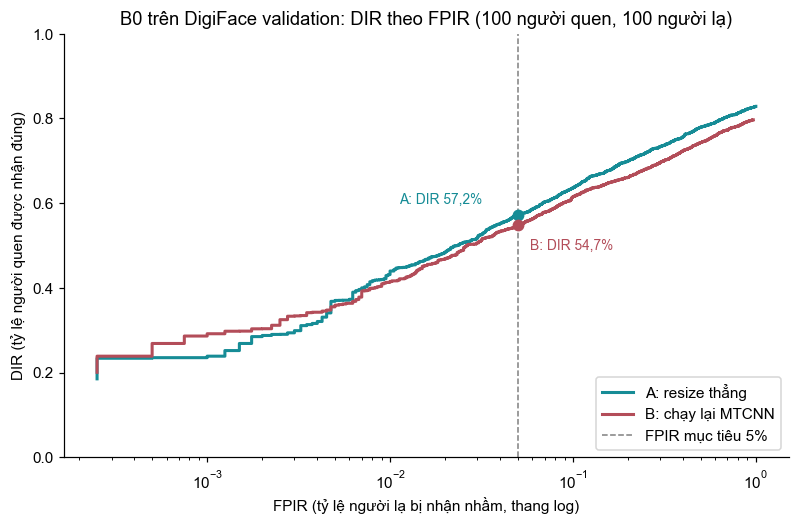

In [7]:
def rates(q, t):
    known, unknown = q[q.is_known], q[~q.is_known]
    acc_k = known.prepared & (known.top_score >= t)
    acc_u = unknown.prepared & (unknown.top_score >= t)
    return {'DIR': (acc_k & known.top1_correct).sum()/len(known), 'FPIR': acc_u.sum()/len(unknown),
            'correct_accepted': int((acc_k & known.top1_correct).sum()),
            'wrong_identity_accepted': int((acc_k & ~known.top1_correct).sum()),
            'known_rejected_by_threshold': int((known.prepared & ~acc_k).sum()),
            'known_preparation_failed': int((~known.prepared).sum()),
            'unknown_accepted': int(acc_u.sum()), 'unknown_rejected': int((unknown.prepared & ~acc_u).sum()),
            'unknown_preparation_failed': int((~unknown.prepared).sum()),
            'known_queries': len(known), 'unknown_queries': len(unknown)}

def curve(q):
    s = np.sort(q.loc[q.prepared, 'top_score'].unique())
    cand = np.concatenate([s, [np.inf]])
    known, unknown = q[q.is_known], q[~q.is_known]
    ks = np.sort(known.loc[known.prepared & known.top1_correct, 'top_score'].to_numpy())
    us = np.sort(unknown.loc[unknown.prepared, 'top_score'].to_numpy())
    dir_ = (len(ks) - np.searchsorted(ks, cand, side='left'))/len(known)
    fpir = (len(us) - np.searchsorted(us, cand, side='left'))/len(unknown)
    return pd.DataFrame({'threshold': cand, 'DIR': dir_, 'FPIR': fpir})

operating, curves = [], {}
for k in 'AB':
    c = curves[k] = curve(scores[k])
    feasible = c[c.FPIR <= FPIR_TARGET]
    best = feasible[feasible.DIR == feasible.DIR.max()].threshold.max()
    r = rates(scores[k], best)
    assert abs(r['DIR'] - feasible.DIR.max()) < 1e-12 and r['FPIR'] <= FPIR_TARGET
    operating.append({'pipeline': k, 'threshold': float(best), **r})
op = save(pd.DataFrame(operating), '04_operating_point_fpir5')
display(op.T)

fig, ax = plt.subplots(figsize=(8.5, 5))
colors = {'A': '#168C96', 'B': '#B34D59'}
labels = {'A': 'A: resize thẳng', 'B': 'B: chạy lại MTCNN'}
for k in 'AB':
    c = curves[k][curves[k].FPIR > 0]
    ax.plot(c.FPIR, c.DIR, color=colors[k], lw=2, label=labels[k])
    o = op[op.pipeline.eq(k)].iloc[0]
    ax.scatter([o.FPIR], [o.DIR], color=colors[k], s=45, zorder=3)
    ax.annotate(f'{labels[k][:1]}: DIR {pct(o.DIR,1)}', (o.FPIR, o.DIR), textcoords='offset points',
                xytext=(-78, 8) if k == 'A' else (8, -16), fontsize=9, color=colors[k])
ax.axvline(FPIR_TARGET, color='gray', ls='--', lw=1, label='FPIR mục tiêu 5%')
ax.set(xscale='log', xlabel='FPIR (tỷ lệ người lạ bị nhận nhầm, thang log)', ylabel='DIR (tỷ lệ người quen được nhận đúng)',
       title='B0 trên DigiFace validation: DIR theo FPIR (100 người quen, 100 người lạ)', ylim=(0, 1))
ax.legend(loc='lower right'); finish(fig, '04_dir_vs_fpir')

## 8. Khoảng tin cậy theo người

Các query của cùng một người có tương quan, nên bootstrap lấy mẫu lại **người** (giữ mọi query của người được chọn), riêng cho người quen và người lạ, 2.000 lần, với ngưỡng đã chọn ở phần 7. Chênh lệch A − B được tính trên **cùng** bộ người lấy mẫu (bootstrap cặp). Khoảng tin cậy này chưa tính phần bất định do chính việc chọn ngưỡng.

In [8]:
rng = np.random.default_rng(SEED)
thr = dict(zip(op.pipeline, op.threshold))
def per_identity(k):
    q = scores[k]; t = thr[k]
    acc = q.prepared & (q.top_score >= t)
    q = q.assign(hit=acc & q.top1_correct, fa=acc & ~q.is_known)
    kn = q[q.is_known].groupby('canonical_identity').agg(hit=('hit', 'sum'), n=('hit', 'size')).reindex(known_ids)
    un = q[~q.is_known].groupby('canonical_identity').agg(fa=('fa', 'sum'), n=('fa', 'size')).reindex(unknown_ids)
    return kn.to_numpy(float), un.to_numpy(float)
P = {k: per_identity(k) for k in 'AB'}
B_REPS = CONFIG['bootstrap_repetitions']
boot = {k: {'DIR': [], 'FPIR': []} for k in 'AB'}; diff = {'DIR': [], 'FPIR': []}
for _ in range(B_REPS):
    ik = rng.integers(0, len(known_ids), len(known_ids)); iu = rng.integers(0, len(unknown_ids), len(unknown_ids))
    for k in 'AB':
        kn, un = P[k]
        boot[k]['DIR'].append(kn[ik, 0].sum()/kn[ik, 1].sum()); boot[k]['FPIR'].append(un[iu, 0].sum()/un[iu, 1].sum())
    diff['DIR'].append(boot['A']['DIR'][-1] - boot['B']['DIR'][-1]); diff['FPIR'].append(boot['A']['FPIR'][-1] - boot['B']['FPIR'][-1])
ci_rows = []
for k in 'AB':
    o = op[op.pipeline.eq(k)].iloc[0]
    for m in ['DIR', 'FPIR']:
        lo, hi = np.quantile(boot[k][m], [0.025, 0.975])
        ci_rows.append({'pipeline': k, 'metric': m, 'value': o[m], 'ci95_low': lo, 'ci95_high': hi})
for m in ['DIR', 'FPIR']:
    lo, hi = np.quantile(diff[m], [0.025, 0.975])
    ci_rows.append({'pipeline': 'A − B', 'metric': m, 'value': op.set_index('pipeline').at['A', m] - op.set_index('pipeline').at['B', m],
                    'ci95_low': lo, 'ci95_high': hi})
ci = save(pd.DataFrame(ci_rows), '05_bootstrap_ci_by_identity')
display(ci)
dA = ci[(ci.pipeline == 'A − B') & (ci.metric == 'DIR')].iloc[0]
if dA.ci95_low > 0.01 or dA.ci95_high < -0.01:
    verdict = 'khoảng tin cậy của chênh lệch nằm hẳn về một phía 0, khác biệt khá rõ'
elif dA.ci95_low > 0 or dA.ci95_high < 0:
    verdict = ('khoảng tin cậy không chứa 0 nhưng cận gần sát 0, nên kết quả nghiêng về một cách nhưng bằng chứng còn yếu '
               '(CI chưa tính phần bất định do chọn ngưỡng)')
else:
    verdict = 'khoảng tin cậy của chênh lệch chứa 0, chưa đủ bằng chứng để nói cách nào tốt hơn'
display(Markdown(f'DIR của A − B = **{pct(dA.value,1)}** (CI 95%: {pct(dA.ci95_low,1)} → {pct(dA.ci95_high,1)}); {verdict}.'))

,pipeline,metric,value,ci95_low,ci95_high
0,A,DIR,0.571622,0.527568,0.615682
1,A,FPIR,0.050000,0.032250,0.071506
2,B,DIR,0.547297,0.498101,0.593784
3,B,FPIR,0.050000,0.033500,0.070756
4,A − B,DIR,0.024324,0.000270,0.049196
5,A − B,FPIR,0.000000,-0.014000,0.012250


DIR của A − B = **2,4%** (CI 95%: 0,0% → 4,9%); khoảng tin cậy không chứa 0 nhưng cận gần sát 0, nên kết quả nghiêng về một cách nhưng bằng chứng còn yếu (CI chưa tính phần bất định do chọn ngưỡng).

## 9. Phân tích theo tập con

Gallery A và B còn khác số người đăng ký (100/97), nên common-query chưa cô lập hoàn toàn tác động crop khỏi enrollment failure.

- **Tập chung:** chỉ những query mà cả A và B đều chuẩn bị được. So trên tập này giảm ảnh hưởng của ảnh hưởng của *cách crop* khỏi ảnh hưởng của *việc detector bỏ sót ảnh*.
- **Ảnh có cờ QA** (đuôi chất lượng hoặc detector từng thất bại ở EDA) so với ảnh không có cờ. Số ảnh có cờ ít nên chỉ mang tính mô tả.

Mọi tập con dùng đúng ngưỡng đã chọn ở phần 7, không chọn lại.

DIR                FPIR           known_queries         unknown_queries        
pipeline               A         B         A         B             A       B               A       B
subset                                                                                              
Có cờ QA        0.431373  0.441176  0.017391  0.026087         102.0   102.0           115.0   115.0
Không có cờ QA  0.575598  0.550306  0.050965  0.050708        3598.0  3598.0          3885.0  3885.0
Toàn bộ         0.571622  0.547297  0.050000  0.050000        3700.0  3700.0          4000.0  4000.0
Tập chung A∩B   0.579834  0.559392  0.051123  0.051640        3620.0  3620.0          3873.0  3873.0

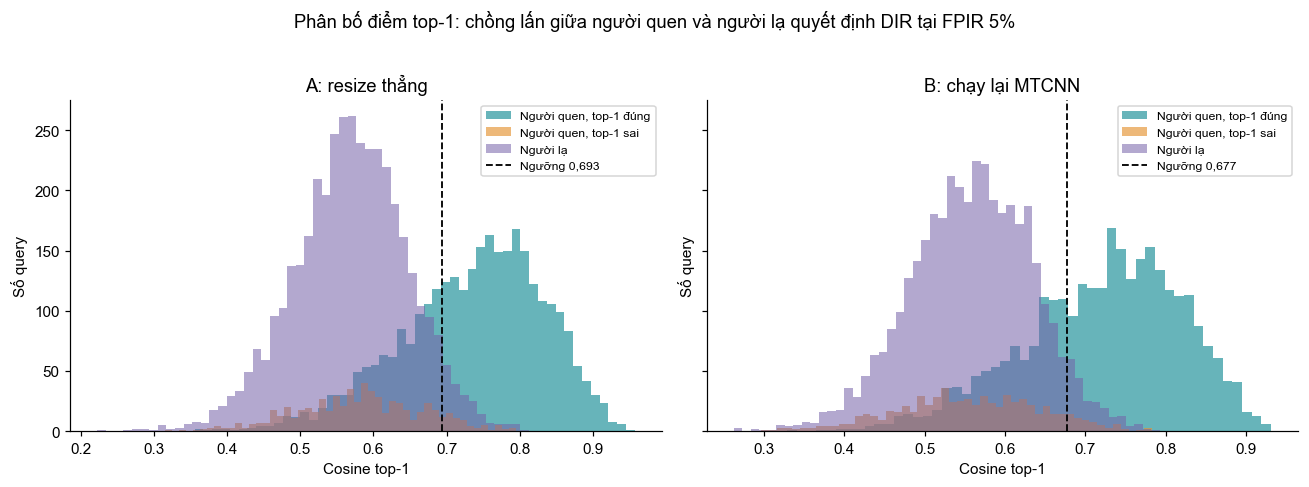

In [9]:
common_ids = set(scores['A'].loc[scores['A'].prepared, 'image_id']) & set(scores['B'].loc[scores['B'].prepared, 'image_id'])
rows = []
for k in 'AB':
    q = scores[k]
    for name, mask in [('Toàn bộ', np.ones(len(q), bool)), ('Tập chung A∩B', q.image_id.isin(common_ids)),
                       ('Có cờ QA', q.qa_flagged), ('Không có cờ QA', ~q.qa_flagged)]:
        sub = q[mask]; r = rates(sub, thr[k])
        rows.append({'pipeline': k, 'subset': name, 'known_queries': r['known_queries'], 'unknown_queries': r['unknown_queries'],
                     'DIR': r['DIR'], 'FPIR': r['FPIR']})
subsets = save(pd.DataFrame(rows), '06_subset_metrics')
display(subsets.pivot(index='subset', columns='pipeline', values=['DIR', 'FPIR', 'known_queries', 'unknown_queries']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, k in zip(axes, 'AB'):
    q = scores[k][scores[k].prepared]
    ax.hist(q.loc[q.top1_correct, 'top_score'], bins=50, alpha=.65, color='#168C96', label='Người quen, top-1 đúng')
    ax.hist(q.loc[q.is_known & ~q.top1_correct, 'top_score'], bins=50, alpha=.65, color='#E49332', label='Người quen, top-1 sai')
    ax.hist(q.loc[~q.is_known, 'top_score'], bins=50, alpha=.55, color='#7561A9', label='Người lạ')
    ax.axvline(thr[k], color='black', ls='--', lw=1.2, label=f'Ngưỡng {vn(thr[k],3)}')
    ax.set(title=labels[k], xlabel='Cosine top-1', ylabel='Số query'); ax.legend(fontsize=8)
fig.suptitle('Phân bố điểm top-1: chồng lấn giữa người quen và người lạ quyết định DIR tại FPIR 5%', y=1.02)
fig.tight_layout(); finish(fig, '06_score_distributions')

## 10. Ví dụ lỗi của B0 (cách A)

Chọn có chủ đích các ca điển hình ở ngưỡng đã chốt: người lạ bị nhận nhầm (điểm cao nhất), người quen bị nhầm sang người khác, người quen bị từ chối (điểm thấp nhất). Mỗi ô ghép ảnh query với một ảnh gallery của người được dự đoán. Hình dùng để hiểu lỗi, không đại diện cho tỷ lệ.

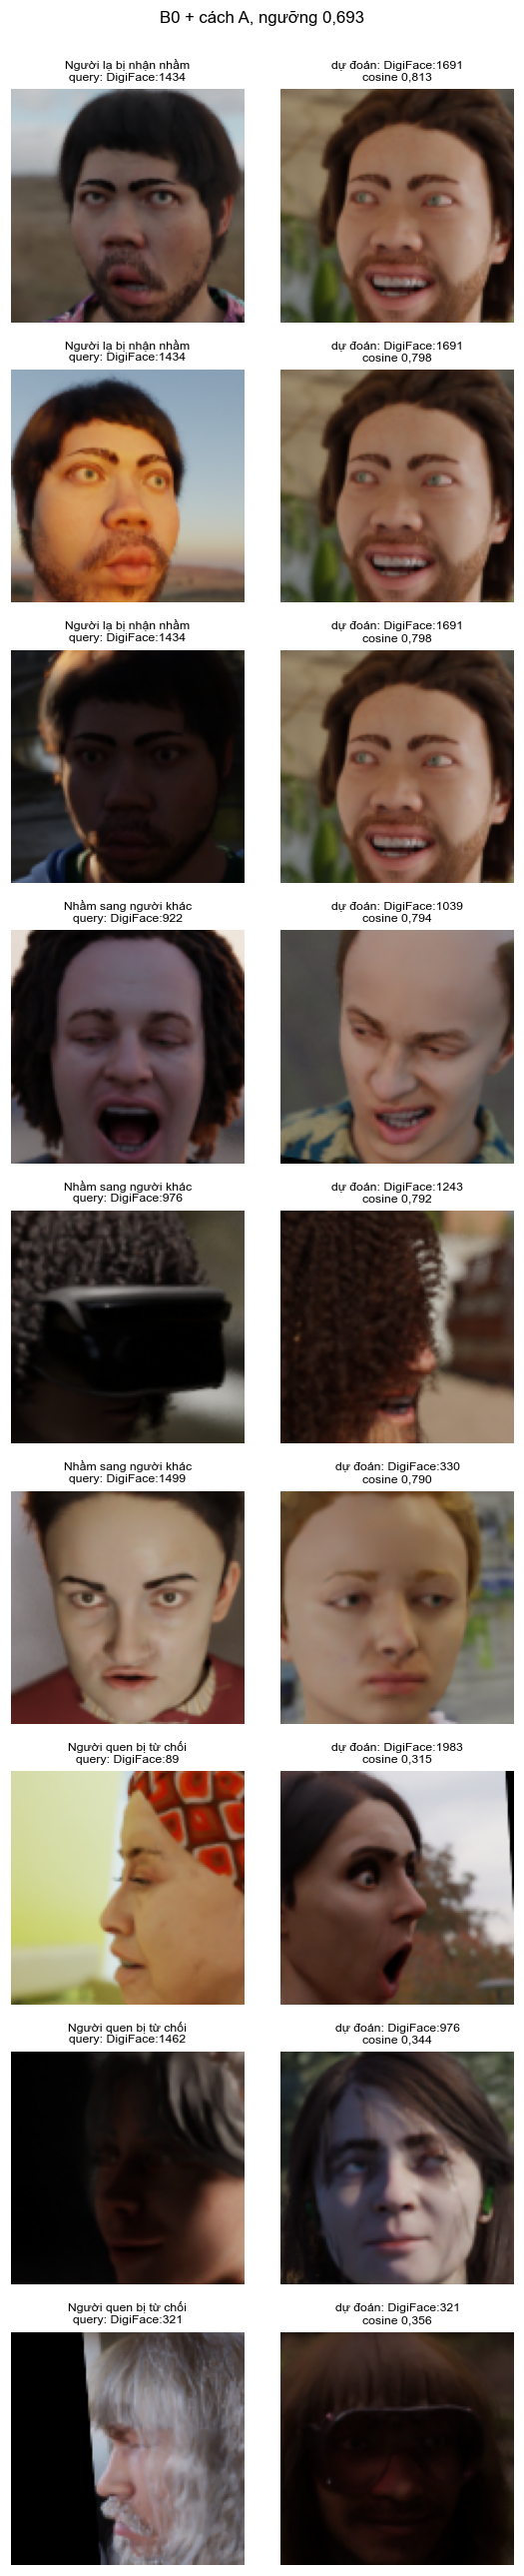

,case,image_id,canonical_identity,top_identity,top_score
4369,Người lạ bị nhận nhầm,DF_8bbde8d358705c4c448f,DigiFace:1434,DigiFace:1691,0.812560
424,Người lạ bị nhận nhầm,DF_0e2ddec1a48eb4f7bcf5,DigiFace:1434,DigiFace:1691,0.798368
294,Người lạ bị nhận nhầm,DF_0a60d48032a928c4b675,DigiFace:1434,DigiFace:1691,0.798111
4138,Nhầm sang người khác,DF_844829a115ba09826184,DigiFace:922,DigiFace:1039,0.794339
324,Nhầm sang người khác,DF_0b5c59ad3d60c3a6a8c8,DigiFace:976,DigiFace:1243,0.791722
4468,Nhầm sang người khác,DF_8ebc2d45f6a92cf53cfe,DigiFace:1499,DigiFace:330,0.789954
7243,Người quen bị từ chối,DF_e945f62c217f1ec45636,DigiFace:89,DigiFace:1983,0.315061
298,Người quen bị từ chối,DF_0a8e89ef31bcd5612257,DigiFace:1462,DigiFace:976,0.343528
7403,Người quen bị từ chối,DF_ee4445be41cc7bf9e075,DigiFace:321,DigiFace:321,0.355734


In [10]:
qa_ = scores['A']; tA = thr['A']
acc = qa_.prepared & (qa_.top_score >= tA)
cases = pd.concat([
    qa_[~qa_.is_known & acc].nlargest(3, 'top_score').assign(case='Người lạ bị nhận nhầm'),
    qa_[qa_.is_known & acc & ~qa_.top1_correct].nlargest(3, 'top_score').assign(case='Nhầm sang người khác'),
    qa_[qa_.is_known & qa_.prepared & ~acc].nsmallest(3, 'top_score').assign(case='Người quen bị từ chối'),
])
gallery_first = V[V.role.eq('gallery')].drop_duplicates('canonical_identity').set_index('canonical_identity')
fig, axes = plt.subplots(len(cases), 2, figsize=(5.2, 2.6*len(cases)), squeeze=False)
for row_axes, r in zip(axes, cases.itertuples()):
    q_im = open_rgb(ROOT/r.path, lookup.at[r.image_id, 'sha256'])
    g = gallery_first.loc[r.top_identity]
    g_im = open_rgb(ROOT/g.path, g.sha256)
    row_axes[0].imshow(q_im); row_axes[0].set_title(f'{r.case}\nquery: {r.canonical_identity}', fontsize=8)
    row_axes[1].imshow(g_im); row_axes[1].set_title(f'dự đoán: {r.top_identity}\ncosine {vn(r.top_score,3)}', fontsize=8)
    for ax in row_axes: ax.axis('off')
fig.suptitle(f'B0 + cách A, ngưỡng {vn(tA,3)}', y=1.0, fontsize=11)
fig.tight_layout(); finish(fig, '07_error_examples_A')
save(cases[['case', 'image_id', 'canonical_identity', 'top_identity', 'top_score']], '07_error_example_selection')

## 11. Kết luận, ngưỡng validation và tệp bàn giao

Bảng dự đoán từng query theo schema thống nhất (`predictions.csv`) và cấu hình ngưỡng validation được lưu để B1/B2 dùng **cùng evaluator, cùng cohort, cùng quy tắc**. Ngưỡng này **chưa được dùng trên test**; ở bước 7 mỗi model đã khóa sẽ áp ngưỡng validation của chính nó lên test.

In [11]:
pred = pd.concat([scores[k].assign(threshold=thr[k]) for k in 'AB'])
pred['run_id'] = 'B0_vggface2_' + pred.pipeline
pred['accepted'] = pred.prepared & (pred.top_score >= pred.threshold)
pred['status'] = np.where(~pred.prepared, 'preparation_failed', np.where(pred.accepted, 'accepted', 'rejected_unknown'))
pred['predicted_identity'] = np.where(pred.accepted, pred.top_identity, 'Unknown')
pred['correct'] = np.where(pred.is_known, pred.accepted & pred.top1_correct, ~pred.accepted)
pred = pred.rename(columns={'image_id': 'query_id', 'canonical_identity': 'true_identity'})
save(pred[['run_id', 'query_id', 'true_identity', 'is_known', 'status', 'predicted_identity', 'top_identity', 'top_score',
           'threshold', 'correct', 'prepared', 'enrolled', 'qa_flagged']], '08_predictions')
assert pred.groupby('run_id').size().eq(7700).all()

opA = op.set_index('pipeline').loc['A']; opB = op.set_index('pipeline').loc['B']
ciA = ci.set_index(['pipeline', 'metric'])
threshold_cfg = {'status': 'validation_selected_not_applied_to_test', 'protocol_version': protocol['version'],
    'fpir_target': FPIR_TARGET, 'gallery_identities': 100, 'gallery_images_per_identity': 3,
    'encoder': CONFIG['encoder'], 'encoder_state_sha256': ENCODER_SHA,
    'runs': {f'B0_{k}': {'pipeline': CONFIG['pipelines'][k], 'threshold': float(thr[k]),
                         'DIR_val': float(op.set_index('pipeline').at[k, 'DIR']), 'FPIR_val': float(op.set_index('pipeline').at[k, 'FPIR'])}
             for k in 'AB'},
    'primary_run': 'B0_A (theo quyết định P5)'}
json_out(threshold_cfg, 'b0_validation_thresholds.json')

for r in V.sample(n=40, random_state=SEED).itertuples(): assert sha(ROOT/r.path) == r.sha256, 'Ảnh gốc đổi trong lúc chạy'
summary = {'checks': 'PASS', 'mode': MODE, 'fingerprint': FINGERPRINT, 'val_content_sha256': VAL_SHA,
    'images': len(V), 'prepared_A': int((V.status_A == 'prepared').sum()), 'prepared_B': int((V.status_B == 'prepared').sum()),
    'enrolled_A': int(summary_enroll.at['A', 'enrolled']), 'enrolled_B': int(summary_enroll.at['B', 'enrolled']),
    'threshold_A': float(thr['A']), 'DIR_A': float(opA.DIR), 'FPIR_A': float(opA.FPIR),
    'threshold_B': float(thr['B']), 'DIR_B': float(opB.DIR), 'FPIR_B': float(opB.FPIR),
    'rank1_closed_set': rank1.set_index('pipeline').rank1_all_known.to_dict(),
    'train_or_test_images_used': False, 'external_images_used': False, 'fine_tuning': False, 'all_raw_validation_hashed_now': len(verified_raw), 'score_export': '17_significant_digits',
    'decisions_P1_P5': expected_choice, 'notebook_source_sha256': NOTEBOOK_SOURCE_SHA,
    'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': round(time.perf_counter()-STARTED, 1)}
json_out(summary, 'execution_summary.json')
save(pd.DataFrame([{'path': p.relative_to(OUT).as_posix(), 'bytes': p.stat().st_size, 'sha256': sha(p)}
                   for p in sorted(OUT.rglob('*')) if p.is_file() and 'cache' not in p.parts and p.name != '09_artifact_hashes.csv']),
     '09_artifact_hashes')

display(Markdown(f"""### Kết quả B0 trên DigiFace validation

| | A: resize thẳng | B: chạy lại MTCNN |
|---|---|---|
| Ảnh chuẩn bị được | {vn(summary['prepared_A'])}/{vn(len(V))} | {vn(summary['prepared_B'])}/{vn(len(V))} |
| Người đăng ký được | {summary['enrolled_A']}/100 | {summary['enrolled_B']}/100 |
| Rank-1 closed-set (tham khảo) | {pct(rank1.set_index('pipeline').at['A','rank1_all_known'],1)} | {pct(rank1.set_index('pipeline').at['B','rank1_all_known'],1)} |
| Ngưỡng cosine (FPIR ≤ 5%) | {vn(thr['A'],3)} | {vn(thr['B'],3)} |
| **DIR tại ngưỡng** | **{pct(opA.DIR,1)}** (CI 95% {pct(ciA.at[('A','DIR'),'ci95_low'],1)}–{pct(ciA.at[('A','DIR'),'ci95_high'],1)}) | **{pct(opB.DIR,1)}** (CI 95% {pct(ciA.at[('B','DIR'),'ci95_low'],1)}–{pct(ciA.at[('B','DIR'),'ci95_high'],1)}) |
| FPIR thực đo | {pct(opA.FPIR,2)} | {pct(opB.FPIR,2)} |

**Đọc kết quả:** {verdict}. B0 được pretrain trên ảnh người thật (VGGFace2), còn DigiFace là ảnh render; mức DIR này là điểm xuất phát mà B1/B2 (fine-tune trên DigiFace train) phải vượt qua trên đúng cohort và evaluator này. Đây chưa phải kết quả trên ảnh che thật (ROF/MFR2 để dành cho bước 7) và chưa phải kết quả webcam.

**Bước tiếp theo (6):** sinh che nhân tạo có kiểm soát cho validation/test và train B1 (dữ liệu nền) / B2 (dữ liệu nền + che) cùng ngân sách, rồi chạy lại notebook này với encoder đã fine-tune.
"""))

# So score bằng đúng float32 của phép tính; export 17 chữ số giữ nguyên số biên.
roundtrip=pd.read_csv(TAB/'08_predictions.csv',float_precision='round_trip')
accepted_rt=roundtrip.prepared.to_numpy(bool) & (roundtrip.top_score.to_numpy(np.float32)>=roundtrip.threshold.to_numpy(np.float32))
accepted_original=pred.prepared.to_numpy(bool) & (pred.top_score.to_numpy(np.float32)>=pred.threshold.to_numpy(np.float32))
assert np.array_equal(accepted_rt,accepted_original), 'CSV round-trip làm đổi quyết định'
for run,g in roundtrip.assign(accepted_rt=accepted_rt).groupby('run_id'):
    pipe=run[-1];hits=int((g.is_known & g.accepted_rt & g.top_identity.eq(g.true_identity)).sum())
    assert hits==int(op.set_index('pipeline').at[pipe,'correct_accepted'])
json_out({'checks':'PASS','score_dtype':'float32','export_significant_digits':17,
          'predictions':len(roundtrip),'decisions_changed_after_roundtrip':int((accepted_rt!=accepted_original).sum())},'score_roundtrip_validation.json')


### Kết quả B0 trên DigiFace validation

| | A: resize thẳng | B: chạy lại MTCNN |
|---|---|---|
| Ảnh chuẩn bị được | 8.000/8.000 | 7.789/8.000 |
| Người đăng ký được | 100/100 | 97/100 |
| Rank-1 closed-set (tham khảo) | 82,9% | 79,7% |
| Ngưỡng cosine (FPIR ≤ 5%) | 0,693 | 0,677 |
| **DIR tại ngưỡng** | **57,2%** (CI 95% 52,8%–61,6%) | **54,7%** (CI 95% 49,8%–59,4%) |
| FPIR thực đo | 5,00% | 5,00% |

**Đọc kết quả:** khoảng tin cậy không chứa 0 nhưng cận gần sát 0, nên kết quả nghiêng về một cách nhưng bằng chứng còn yếu (CI chưa tính phần bất định do chọn ngưỡng). B0 được pretrain trên ảnh người thật (VGGFace2), còn DigiFace là ảnh render; mức DIR này là điểm xuất phát mà B1/B2 (fine-tune trên DigiFace train) phải vượt qua trên đúng cohort và evaluator này. Đây chưa phải kết quả trên ảnh che thật (ROF/MFR2 để dành cho bước 7) và chưa phải kết quả webcam.

**Bước tiếp theo (6):** sinh che nhân tạo có kiểm soát cho validation/test và train B1 (dữ liệu nền) / B2 (dữ liệu nền + che) cùng ngân sách, rồi chạy lại notebook này với encoder đã fine-tune.


## 12. Tệp đầu ra

- `tables/01_preparation_by_role.csv`, `02_enrollment.csv`: số ảnh chuẩn bị được và người đăng ký được theo từng cách.
- `tables/04_operating_point_fpir5.csv`: ngưỡng, DIR, FPIR và đếm từng loại kết quả (đúng, nhầm người, bị từ chối, lỗi chuẩn bị).
- `tables/05_bootstrap_ci_by_identity.csv`: khoảng tin cậy 95% theo người và chênh lệch A − B.
- `tables/06_subset_metrics.csv`: tập chung A∩B, ảnh có/không có cờ QA.
- `tables/08_predictions.csv`: dự đoán từng query (schema dùng chung cho B1/B2).
- `b0_validation_thresholds.json`: ngưỡng validation của B0, chưa áp lên test.
- `figures/`: đường DIR–FPIR, phân bố điểm, ví dụ lỗi.
- `cache/`: embedding đã tính (không gửi kèm ZIP), chỉ dùng lại khi dấu vân tay khớp.